# Depressive Disorder — Deep Dive Analysis
**Database:** `data/synthetic_snuh.duckdb`  
**Condition:** Depressive disorder (F32)  
**Goal:** Understand the patient population, treatment patterns, co-morbidities and dataset limitations before defining a causal question.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.1f}'.format)

DB_PATH = r'c:\Users\33633\Desktop\Efrei\M2\Stage\K-OMOP-CDM\data\synthetic_snuh.duckdb'
con = duckdb.connect(DB_PATH, read_only=True)

# Reusable CTE for depressive disorder patients
DEP_CTE = """
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
"""

n_dep = con.execute("""
    SELECT COUNT(DISTINCT co.person_id)
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
""").fetchone()[0]

print(f'Connected: {DB_PATH}')
print(f'Depressive disorder patients: {n_dep:,}')

Connected: c:\Users\33633\Desktop\Efrei\M2\Stage\K-OMOP-CDM\data\synthetic_snuh.duckdb
Depressive disorder patients: 1,376


## 1. Distribution Issues
Four structural problems that impact causal analysis feasibility.

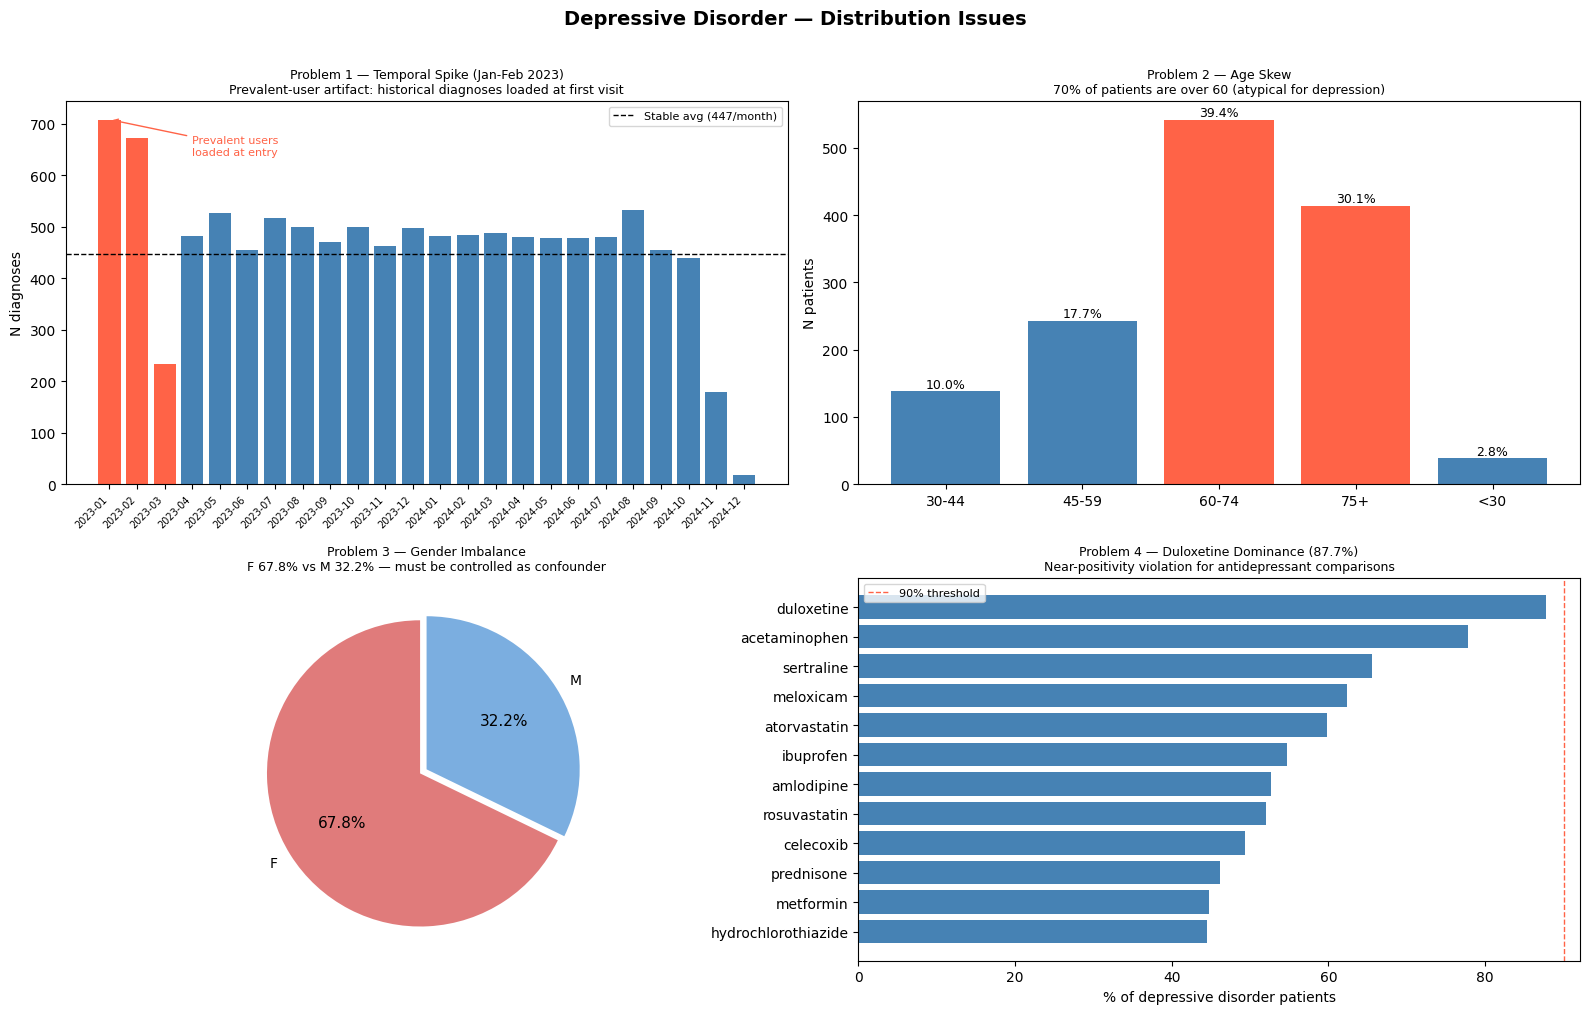

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Depressive Disorder — Distribution Issues', fontsize=14, fontweight='bold', y=1.01)

# ── 1. Temporal spike ────────────────────────────────────────────────────────
df_temporal = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id,
               DATE_TRUNC('month', co.condition_start_date) AS month
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT month, COUNT(*) AS n FROM dep GROUP BY 1 ORDER BY 1
""").df()

colors_temp = ['tomato' if str(m)[:7] in ('2023-01', '2023-02', '2023-03') else 'steelblue'
               for m in df_temporal['month']]
axes[0,0].bar(range(len(df_temporal)), df_temporal['n'], color=colors_temp)
axes[0,0].set_xticks(range(len(df_temporal)))
axes[0,0].set_xticklabels([str(m)[:7] for m in df_temporal['month']], rotation=45, ha='right', fontsize=7)
stable_avg = df_temporal['n'][3:].mean()
axes[0,0].axhline(stable_avg, color='black', linestyle='--', linewidth=1,
                  label=f'Stable avg ({stable_avg:.0f}/month)')
axes[0,0].set_title('Problem 1 — Temporal Spike (Jan-Feb 2023)\nPrevalent-user artifact: historical diagnoses loaded at first visit', fontsize=9)
axes[0,0].set_ylabel('N diagnoses')
axes[0,0].legend(fontsize=8)
axes[0,0].annotate('Prevalent users\nloaded at entry', xy=(0, 708), xytext=(3, 640),
                   arrowprops=dict(arrowstyle='->', color='tomato'), color='tomato', fontsize=8)

# ── 2. Age skew ───────────────────────────────────────────────────────────────
df_age = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT CASE WHEN (2024-p.year_of_birth)<30  THEN '<30'
                WHEN (2024-p.year_of_birth)<45  THEN '30-44'
                WHEN (2024-p.year_of_birth)<60  THEN '45-59'
                WHEN (2024-p.year_of_birth)<75  THEN '60-74'
                ELSE '75+' END AS age_group,
           COUNT(*) AS n
    FROM main.person p WHERE p.person_id IN (SELECT person_id FROM dep)
    GROUP BY 1 ORDER BY 1
""").df()

colors_age = ['tomato' if g in ('60-74', '75+') else 'steelblue' for g in df_age['age_group']]
bars = axes[0,1].bar(df_age['age_group'], df_age['n'], color=colors_age)
axes[0,1].set_title('Problem 2 — Age Skew\n70% of patients are over 60 (atypical for depression)', fontsize=9)
axes[0,1].set_ylabel('N patients')
for bar, row in zip(bars, df_age.itertuples()):
    pct = row.n / df_age['n'].sum() * 100
    axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                   f'{pct:.1f}%', ha='center', fontsize=9)

# ── 3. Gender imbalance ───────────────────────────────────────────────────────
df_gender = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT p.gender_source_value AS gender, COUNT(*) AS n
    FROM main.person p WHERE p.person_id IN (SELECT person_id FROM dep)
    GROUP BY 1 ORDER BY 2 DESC
""").df()

wedges, texts, autotexts = axes[1,0].pie(
    df_gender['n'], labels=df_gender['gender'],
    autopct='%1.1f%%', colors=['#e07b7b','#7baee0'],
    startangle=90, explode=[0.05, 0]
)
for at in autotexts: at.set_fontsize(11)
axes[1,0].set_title('Problem 3 — Gender Imbalance\nF 67.8% vs M 32.2% — must be controlled as confounder', fontsize=9)

# ── 4. Drug dominance ────────────────────────────────────────────────────────
df_dom = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS drug,
           ROUND(COUNT(DISTINCT de.person_id)*100.0/(SELECT COUNT(*) FROM dep),1) AS pct
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM dep)
      AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 12
""").df()

axes[1,1].barh(df_dom['drug'][::-1], df_dom['pct'][::-1], color='steelblue')
axes[1,1].set_xlabel('% of depressive disorder patients')
axes[1,1].set_title('Problem 4 — Duloxetine Dominance (87.7%)\nNear-positivity violation for antidepressant comparisons', fontsize=9)
axes[1,1].axvline(90, color='tomato', linestyle='--', linewidth=1, label='90% threshold')
axes[1,1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('depressive_disorder_distribution_issues.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Complete Drug List
All drugs prescribed to depressive disorder patients. ATC vocabulary not loaded — no automatic class hierarchy available.

In [3]:
df_dep_drugs = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT
        c.concept_name                                           AS drug,
        c.concept_class_id                                       AS drug_class,
        c.vocabulary_id                                          AS vocabulary,
        COUNT(DISTINCT de.person_id)                             AS n_patients,
        COUNT(*)                                                 AS n_prescriptions,
        ROUND(COUNT(DISTINCT de.person_id)*100.0 /
              (SELECT COUNT(*) FROM dep), 1)                     AS pct
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM dep)
      AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
    GROUP BY 1, 2, 3
    ORDER BY n_patients DESC
""").df()

print(f'Total distinct drugs: {len(df_dep_drugs)}')
df_dep_drugs

Total distinct drugs: 184


,drug,drug_class,vocabulary,n_patients,n_prescriptions,pct
0,duloxetine,Ingredient,RxNorm,1207,2887,87.7
1,acetaminophen,Ingredient,RxNorm,1071,2872,77.8
2,sertraline,Ingredient,RxNorm,903,1456,65.6
3,meloxicam,Ingredient,RxNorm,859,1920,62.4
4,atorvastatin,Ingredient,RxNorm,823,1563,59.8
...,...,...,...,...,...,...
179,clobetasol propionate 0.5 MG/ML Topical Foam,Clinical Drug,RxNorm,2,2,0.1
180,PRANLUKAST,Ingredient,RxNorm Extension,2,2,0.1
181,tranilast,Ingredient,RxNorm,2,2,0.1
182,urea,Ingredient,RxNorm,1,1,0.1


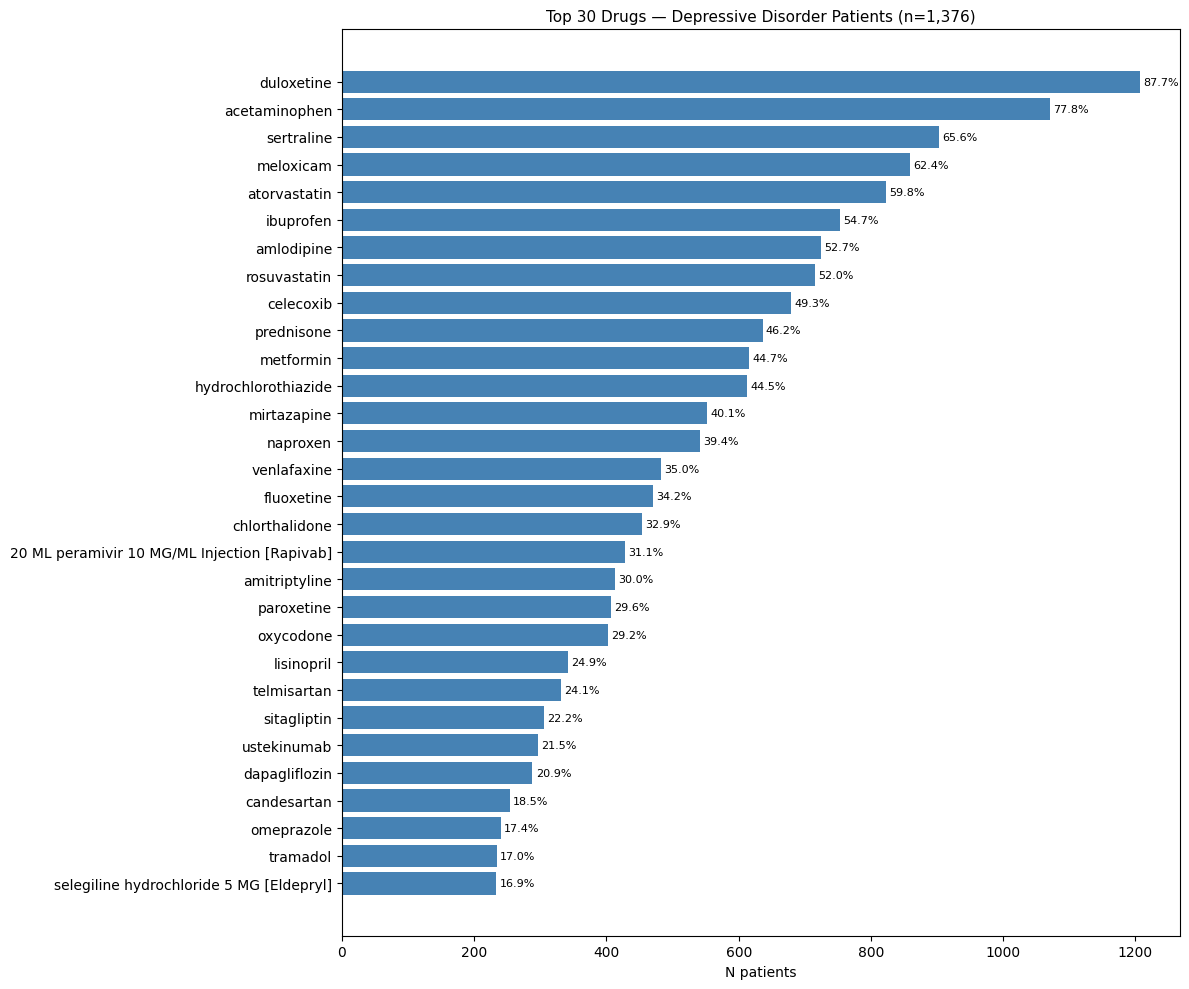

In [4]:
# Top 30 — bar chart
top30 = df_dep_drugs.head(30)

fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(top30['drug'][::-1], top30['n_patients'][::-1], color='steelblue')
ax.set_xlabel('N patients')
ax.set_title('Top 30 Drugs — Depressive Disorder Patients (n=1,376)', fontsize=11)
for i, (_, row) in enumerate(top30[::-1].reset_index().iterrows()):
    ax.text(row['n_patients'] + 5, i, f"{row['pct']}%", va='center', fontsize=8)
plt.tight_layout()
plt.savefig('depressive_disorder_drug_list.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Treatment Changes per Patient
How many distinct drugs does each patient receive? Which patients have the most treatment changes?

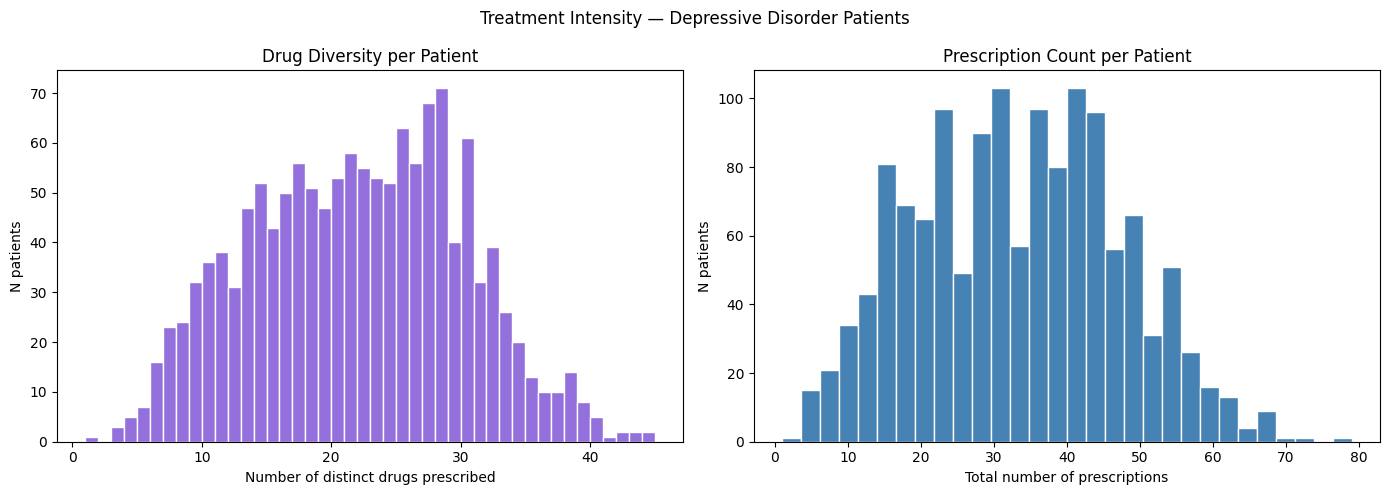

Avg distinct drugs : 21.5
Median            : 22
Max               : 44


In [5]:
df_drug_count = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT de.person_id,
           COUNT(DISTINCT de.drug_concept_id) AS n_distinct_drugs,
           COUNT(*)                            AS n_prescriptions,
           MIN(de.drug_exposure_start_date)    AS first_rx,
           MAX(de.drug_exposure_start_date)    AS last_rx
    FROM main.drug_exposure de
    WHERE de.person_id IN (SELECT person_id FROM dep) AND de.drug_concept_id != 0
    GROUP BY de.person_id
""").df()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_drug_count['n_distinct_drugs'],
             bins=range(1, df_drug_count['n_distinct_drugs'].max()+2),
             color='mediumpurple', edgecolor='white')
axes[0].set_xlabel('Number of distinct drugs prescribed')
axes[0].set_ylabel('N patients')
axes[0].set_title('Drug Diversity per Patient')

axes[1].hist(df_drug_count['n_prescriptions'],
             bins=30, color='steelblue', edgecolor='white')
axes[1].set_xlabel('Total number of prescriptions')
axes[1].set_ylabel('N patients')
axes[1].set_title('Prescription Count per Patient')

plt.suptitle('Treatment Intensity — Depressive Disorder Patients', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Avg distinct drugs : {df_drug_count['n_distinct_drugs'].mean():.1f}")
print(f"Median            : {df_drug_count['n_distinct_drugs'].median():.0f}")
print(f"Max               : {df_drug_count['n_distinct_drugs'].max()}")

In [6]:
# Top 10 patients with most distinct drugs
print('Top 10 patients — most treatment changes (distinct drugs):')
df_drug_count.sort_values('n_distinct_drugs', ascending=False).head(10).reset_index(drop=True)

Top 10 patients — most treatment changes (distinct drugs):


,person_id,n_distinct_drugs,n_prescriptions,first_rx,last_rx
0,9890,44,68,2023-01-03,2024-12-09
1,4168,44,69,2023-01-08,2024-11-18
2,9479,43,57,2023-01-12,2024-12-01
3,7590,43,79,2023-01-11,2024-12-02
4,4731,42,62,2023-01-07,2024-10-23
5,545,42,65,2023-01-04,2024-10-21
6,4236,41,60,2023-01-14,2024-12-20
7,3747,40,56,2023-01-06,2024-11-26
8,8781,40,59,2023-01-22,2024-10-20
9,3619,40,53,2023-01-01,2024-10-28


## 4. Co-morbidities
Which other conditions are most common among depressive disorder patients?

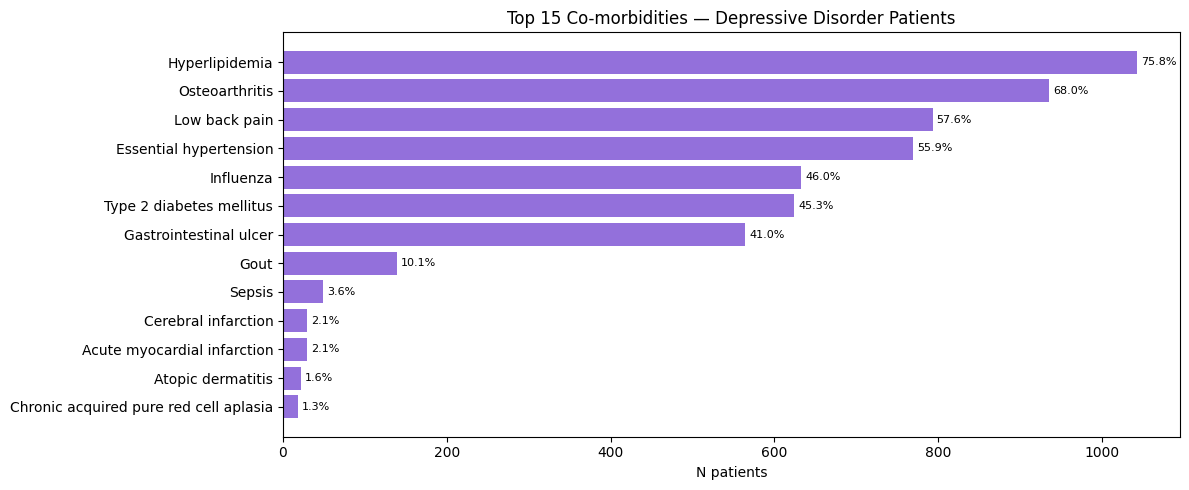

,condition,n_patients,pct
0,Hyperlipidemia,1043,75.8
1,Osteoarthritis,935,68.0
2,Low back pain,793,57.6
3,Essential hypertension,769,55.9
4,Influenza,633,46.0
5,Type 2 diabetes mellitus,624,45.3
6,Gastrointestinal ulcer,564,41.0
7,Gout,139,10.1
8,Sepsis,49,3.6
9,Cerebral infarction,29,2.1


In [7]:
df_comorbid = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS condition,
           COUNT(DISTINCT co.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT co.person_id)*100.0/(SELECT COUNT(*) FROM dep),1) AS pct
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id IN (SELECT person_id FROM dep)
      AND c.concept_name NOT ILIKE '%depressive%'
      AND c.standard_concept = 'S'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 15
""").df()

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(df_comorbid['condition'][::-1], df_comorbid['n_patients'][::-1], color='mediumpurple')
ax.set_xlabel('N patients')
ax.set_title('Top 15 Co-morbidities — Depressive Disorder Patients')
for i, (_, row) in enumerate(df_comorbid[::-1].reset_index().iterrows()):
    ax.text(row['n_patients'] + 5, i, f"{row['pct']}%", va='center', fontsize=8)
plt.tight_layout()
plt.show()

df_comorbid

## 5. Observations
What observations are recorded for depressive disorder patients? Coverage check + single-patient profile.

In [8]:
# Observation coverage
obs_cov = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT
        COUNT(DISTINCT dp.person_id) AS total_patients,
        COUNT(DISTINCT o.person_id)  AS patients_with_obs,
        ROUND(COUNT(DISTINCT o.person_id)*100.0 / COUNT(DISTINCT dp.person_id), 1) AS pct_coverage
    FROM dep dp
    LEFT JOIN main.observation o ON dp.person_id = o.person_id
""").df()
print('Observation coverage:')
print(obs_cov.to_string(index=False))

# Patient with most observations
top_obs_patient = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT o.person_id, COUNT(*) AS n_obs
    FROM main.observation o
    WHERE o.person_id IN (SELECT person_id FROM dep)
    GROUP BY o.person_id ORDER BY n_obs DESC LIMIT 1
""").df()

example_pid = int(top_obs_patient['person_id'].iloc[0])
print(f'\nExample patient: {example_pid} — {int(top_obs_patient["n_obs"].iloc[0])} observations')

Observation coverage:
 total_patients  patients_with_obs  pct_coverage
           1376               1376         100.0

Example patient: 8367 — 100 observations


In [9]:
# All observations for the example patient
print(f'All observations — patient {example_pid}:')
df_obs = con.execute(f"""
    SELECT o.observation_date,
           COALESCE(c.concept_name, 'UNMAPPED') AS observation,
           o.observation_source_value,
           o.value_as_string,
           o.value_as_number
    FROM main.observation o
    LEFT JOIN main.concept c ON o.observation_concept_id = c.concept_id
    WHERE o.person_id = {example_pid}
    ORDER BY o.observation_date
""").df()
df_obs

All observations — patient 8367:


,observation_date,observation,observation_source_value,value_as_string,value_as_number
0,2023-01-07,Chronic shoulder pain,HSDN:D020069:Shoulder Pain,present,NaN
1,2023-01-07,Pain threshold,HSDN:D017288:Pain Threshold,present,NaN
2,2023-01-07,Pain,HSDN:D010146:Pain,present,NaN
3,2023-01-27,Fatigue,HSDN:D005221:Fatigue,present,NaN
4,2023-01-27,No matching concept,HSDN:D057774:Post-Exercise Hypotension,present,NaN
...,...,...,...,...,...
95,2024-10-01,Akathisia caused by drug,"HSDN:D017109:Akathisia, Drug-Induced",present,NaN
96,2024-10-05,Pain,HSDN:D010146:Pain,present,NaN
97,2024-10-05,Sciatica,HSDN:D012585:Sciatica,present,NaN
98,2024-10-08,Atherosclerosis,HSDN:D050197:Atherosclerosis,present,NaN


## 6. Full Clinical Profile — Example Patient

In [10]:
print(f'=== Clinical profile — Patient {example_pid} ===\n')

demo = con.execute(f"""
    SELECT year_of_birth, gender_source_value, race_source_value
    FROM main.person WHERE person_id = {example_pid}
""").df()
print(f"Demographics: birth={int(demo.iloc[0]['year_of_birth'])}  "
      f"gender={demo.iloc[0]['gender_source_value']}  "
      f"race={demo.iloc[0]['race_source_value']}\n")

print('── Conditions ──────────────────────────────────────────')
print(con.execute(f"""
    SELECT co.condition_start_date, c.concept_name, co.condition_source_value
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id = {example_pid} ORDER BY co.condition_start_date
""").df().to_string(index=False))

print('\n── Drug timeline ───────────────────────────────────────')
print(con.execute(f"""
    SELECT de.drug_exposure_start_date, de.drug_exposure_end_date, c.concept_name AS drug
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id = {example_pid} ORDER BY de.drug_exposure_start_date
""").df().to_string(index=False))

print('\n── Measurements ────────────────────────────────────────')
print(con.execute(f"""
    SELECT m.measurement_date, c.concept_name AS measure,
           m.value_as_number, m.unit_source_value
    FROM main.measurement m
    JOIN main.concept c ON m.measurement_concept_id = c.concept_id
    WHERE m.person_id = {example_pid} ORDER BY m.measurement_date
""").df().to_string(index=False))

=== Clinical profile — Patient 8367 ===

Demographics: birth=1937  gender=F  race=Other

── Conditions ──────────────────────────────────────────
condition_start_date             concept_name condition_source_value
          2023-01-07           Osteoarthritis                    M17
          2023-01-27   Essential hypertension                    I10
          2023-01-27           Hyperlipidemia                    E78
          2023-02-15      Depressive disorder                    F32
          2023-02-19 Type 2 diabetes mellitus                    E11
          2023-02-24            Low back pain                    M54
          2023-02-28                Influenza                    J00
          2023-03-18                Influenza                    J00
          2023-03-22   Essential hypertension                    I10
          2023-04-25 Type 2 diabetes mellitus                    E11
          2023-04-28           Hyperlipidemia                    E78
          2023-05-08      

In [1]:
con.close()
print('Connection closed.')

NameError: name 'con' is not defined